In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


In [2]:
breast_cancer = load_breast_cancer()


In [31]:
type(breast_cancer)

sklearn.utils._bunch.Bunch

In [3]:
print("Özellikler: ", breast_cancer.feature_names)
print("Hedef: ", breast_cancer.target_names)

Özellikler:  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Hedef:  ['malignant' 'benign']


In [4]:
df = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)


In [5]:
X = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)
y = pd.Series(breast_cancer.target)


In [32]:
corr_matrix = X.corr().abs()

In [33]:
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

In [34]:
print("Elenecek yüksek korelasyonlu özellikler:", to_drop)

Elenecek yüksek korelasyonlu özellikler: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


In [6]:
X.shape

(569, 30)

In [7]:
y.shape

(569,)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [10]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

LogisticRegression()

In [11]:
lr_pred = lr_model.predict(X_test)


In [12]:
lr_accuracy = accuracy_score(y_test, lr_pred) 
lr_classification_rep = classification_report(y_test, lr_pred, target_names=breast_cancer.target_names) 

print ( f"Doğruluk: {lr_accuracy: .2f} " ) 
print ( f"Sınıflandırma Raporu:" ) 
print (lr_classification_rep)

Doğruluk:  0.98 
Sınıflandırma Raporu:
              precision    recall  f1-score   support

   malignant       0.96      0.99      0.97        67
      benign       0.99      0.98      0.98       121

    accuracy                           0.98       188
   macro avg       0.97      0.98      0.98       188
weighted avg       0.98      0.98      0.98       188



In [13]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [14]:
df.shape

(569, 30)

In [15]:
df.dtypes

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [22]:
df.isnull().sum()


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

In [23]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit

In [24]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    if dataframe[(dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)].any(axis=None):
        return True
    else:
        return False

In [25]:
for col in df.columns:
    print(col, check_outlier(df, col))


mean radius True
mean texture True
mean perimeter True
mean area True
mean smoothness True
mean compactness True
mean concavity True
mean concave points True
mean symmetry True
mean fractal dimension True
radius error True
texture error True
perimeter error True
area error True
smoothness error True
compactness error True
concavity error True
concave points error True
symmetry error True
fractal dimension error True
worst radius True
worst texture True
worst perimeter True
worst area True
worst smoothness True
worst compactness True
worst concavity True
worst concave points False
worst symmetry True
worst fractal dimension True


In [26]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")
    
    return cat_cols, num_cols, cat_but_car


In [27]:
cat_cols, num_cols, cat_but_car = grab_col_names(dataframe=df, car_th=5, cat_th=10)

Observations: 569
Variables: 30
cat_cols: 0
num_cols: 30
cat_but_car: 0
num_but_cat: 0


In [28]:
def correlation_matrix(dataframe, cols):
    fig = plt.gcf()
    fig.set_size_inches(10,8)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    fig = sns.heatmap(dataframe[cols].corr(), annot=True, linewidths=0.5, annot_kws={'size': 12}, linecolor='w', cmap='RdBu')
    plt.show(block=True)

In [29]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)

count    569.000000
mean      14.127292
std        3.524049
min        6.981000
5%         9.529200
10%       10.260000
20%       11.366000
30%       12.012000
40%       12.726000
50%       13.370000
60%       14.058000
70%       15.056000
80%       17.068000
90%       19.530000
95%       20.576000
max       28.110000
Name: mean radius, dtype: float64


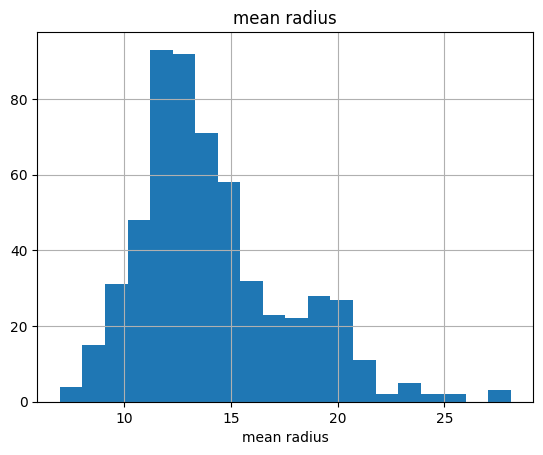

count    569.000000
mean      19.289649
std        4.301036
min        9.710000
5%        13.088000
10%       14.078000
20%       15.656000
30%       16.840000
40%       17.912000
50%       18.840000
60%       19.968000
70%       21.272000
80%       22.440000
90%       24.992000
95%       27.150000
max       39.280000
Name: mean texture, dtype: float64


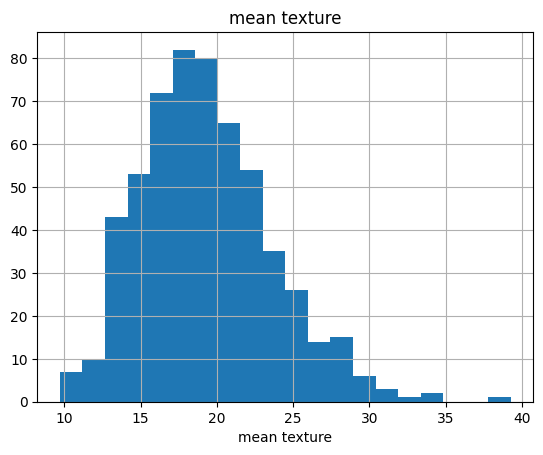

count    569.000000
mean      91.969033
std       24.298981
min       43.790000
5%        60.496000
10%       65.830000
20%       73.292000
30%       77.360000
40%       81.938000
50%       86.240000
60%       91.420000
70%       98.200000
80%      111.680000
90%      129.100000
95%      135.820000
max      188.500000
Name: mean perimeter, dtype: float64


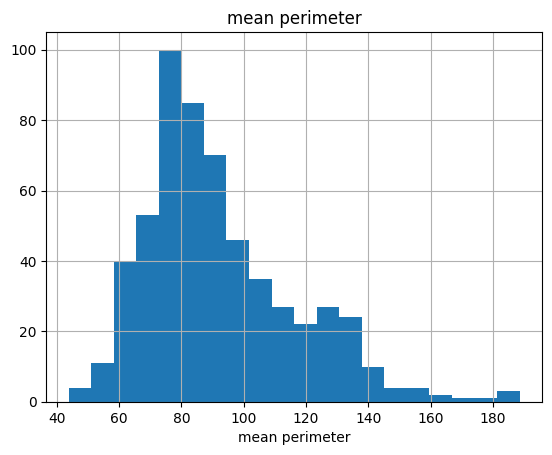

count     569.000000
mean      654.889104
std       351.914129
min       143.500000
5%        275.780000
10%       321.600000
20%       396.560000
30%       444.060000
40%       496.440000
50%       551.100000
60%       609.740000
70%       700.660000
80%       915.060000
90%      1177.400000
95%      1309.800000
max      2501.000000
Name: mean area, dtype: float64


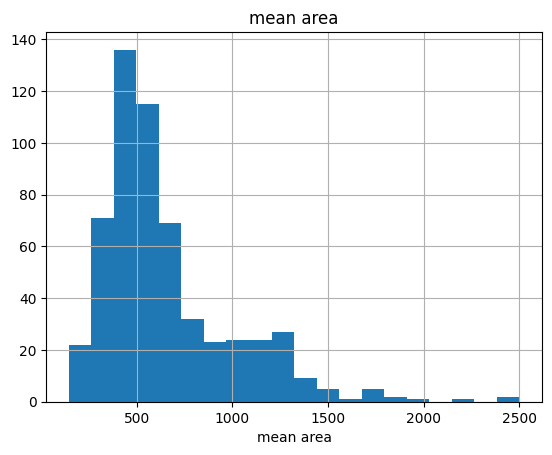

count    569.000000
mean       0.096360
std        0.014064
min        0.052630
5%         0.075042
10%        0.079654
20%        0.084206
30%        0.087914
40%        0.091828
50%        0.095870
60%        0.099338
70%        0.103260
80%        0.107500
90%        0.114820
95%        0.118780
max        0.163400
Name: mean smoothness, dtype: float64


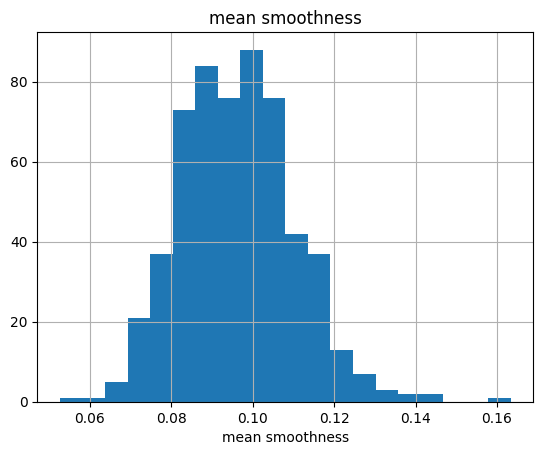

count    569.000000
mean       0.104341
std        0.052813
min        0.019380
5%         0.040660
10%        0.049700
20%        0.059638
30%        0.070390
40%        0.079530
50%        0.092630
60%        0.108740
70%        0.122420
80%        0.141900
90%        0.175460
95%        0.208700
max        0.345400
Name: mean compactness, dtype: float64


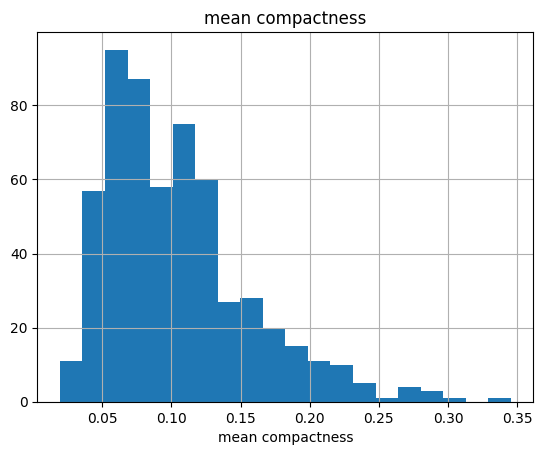

count    569.000000
mean       0.088799
std        0.079720
min        0.000000
5%         0.004983
10%        0.013686
20%        0.024930
30%        0.034400
40%        0.045070
50%        0.061540
60%        0.086212
70%        0.111920
80%        0.149780
90%        0.203040
95%        0.243020
max        0.426800
Name: mean concavity, dtype: float64


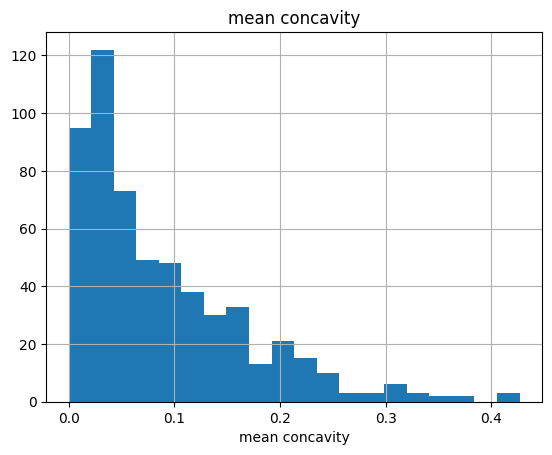

count    569.000000
mean       0.048919
std        0.038803
min        0.000000
5%         0.005621
10%        0.011158
20%        0.017866
30%        0.022788
40%        0.027982
50%        0.033500
60%        0.048318
70%        0.064496
80%        0.084254
90%        0.100420
95%        0.125740
max        0.201200
Name: mean concave points, dtype: float64


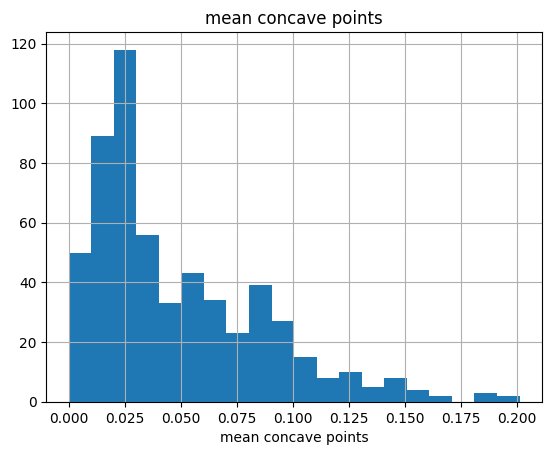

count    569.000000
mean       0.181162
std        0.027414
min        0.106000
5%         0.141500
10%        0.149580
20%        0.158760
30%        0.165080
40%        0.172000
50%        0.179200
60%        0.185480
70%        0.192800
80%        0.200540
90%        0.214940
95%        0.230720
max        0.304000
Name: mean symmetry, dtype: float64


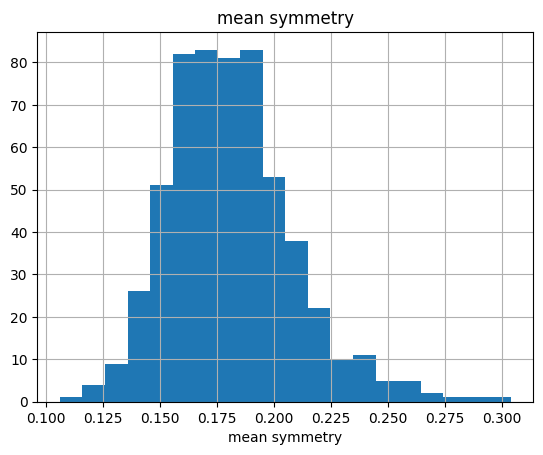

count    569.000000
mean       0.062798
std        0.007060
min        0.049960
5%         0.053926
10%        0.055338
20%        0.056864
30%        0.058840
40%        0.060204
50%        0.061540
60%        0.063148
70%        0.065048
80%        0.067630
90%        0.072266
95%        0.076090
max        0.097440
Name: mean fractal dimension, dtype: float64


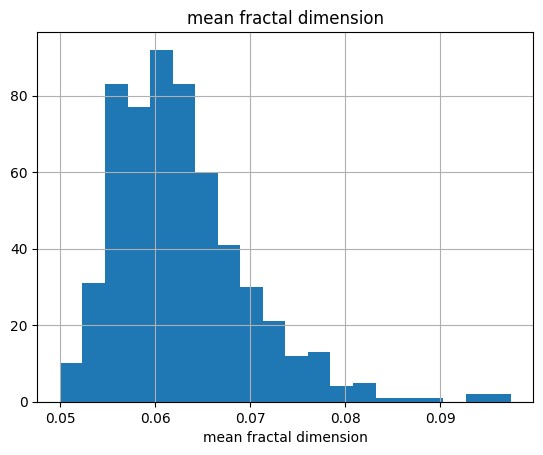

count    569.000000
mean       0.405172
std        0.277313
min        0.111500
5%         0.160100
10%        0.183080
20%        0.219280
30%        0.246040
40%        0.280200
50%        0.324200
60%        0.369460
70%        0.431020
80%        0.546140
90%        0.748880
95%        0.959520
max        2.873000
Name: radius error, dtype: float64


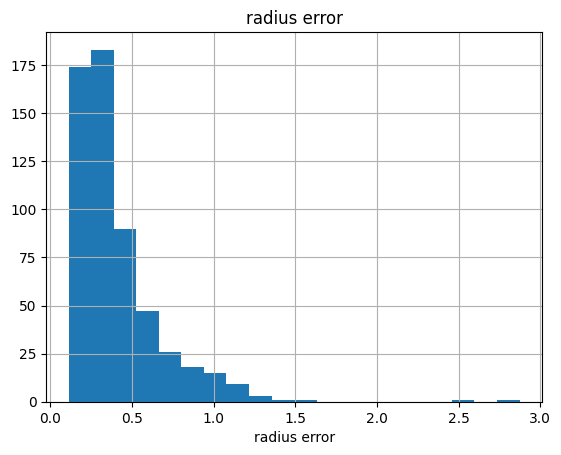

count    569.000000
mean       1.216853
std        0.551648
min        0.360200
5%         0.540140
10%        0.640400
20%        0.780600
30%        0.902100
40%        1.005200
50%        1.108000
60%        1.238800
70%        1.388200
80%        1.561200
90%        1.909400
95%        2.212000
max        4.885000
Name: texture error, dtype: float64


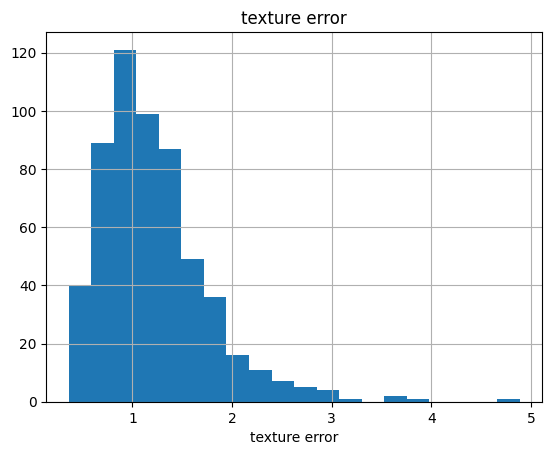

count    569.000000
mean       2.866059
std        2.021855
min        0.757000
5%         1.132800
10%        1.280200
20%        1.516600
30%        1.740800
40%        2.039400
50%        2.287000
60%        2.590800
70%        3.050200
80%        3.767800
90%        5.123200
95%        7.041600
max       21.980000
Name: perimeter error, dtype: float64


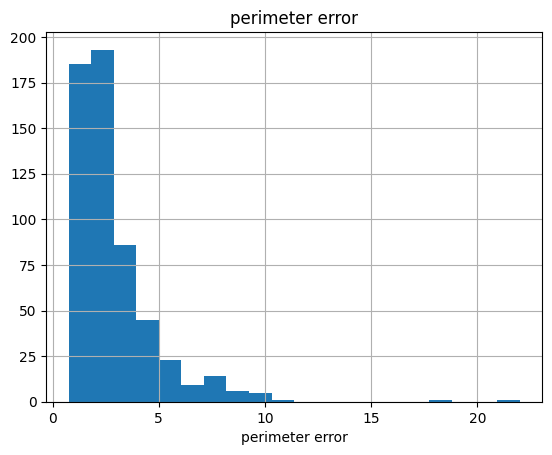

count    569.000000
mean      40.337079
std       45.491006
min        6.802000
5%        11.360000
10%       13.160000
20%       16.640000
30%       19.038000
40%       21.078000
50%       24.530000
60%       29.322000
70%       38.430000
80%       54.088000
90%       91.314000
95%      115.800000
max      542.200000
Name: area error, dtype: float64


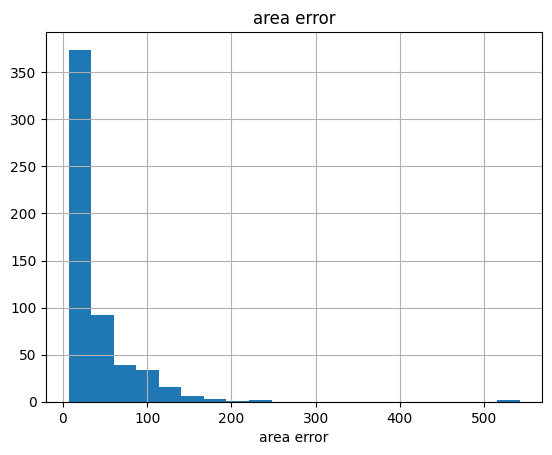

count    569.000000
mean       0.007041
std        0.003003
min        0.001713
5%         0.003690
10%        0.004224
20%        0.004871
30%        0.005417
40%        0.005843
50%        0.006380
60%        0.006944
70%        0.007773
80%        0.008828
90%        0.010410
95%        0.012644
max        0.031130
Name: smoothness error, dtype: float64


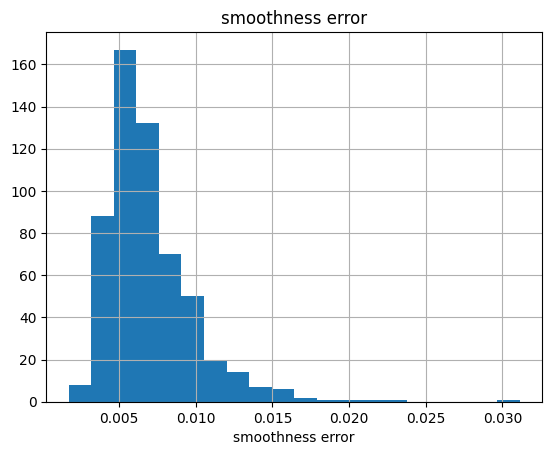

count    569.000000
mean       0.025478
std        0.017908
min        0.002252
5%         0.007892
10%        0.009169
20%        0.011800
30%        0.014240
40%        0.017020
50%        0.020450
60%        0.024480
70%        0.030136
80%        0.036198
90%        0.047602
95%        0.060578
max        0.135400
Name: compactness error, dtype: float64


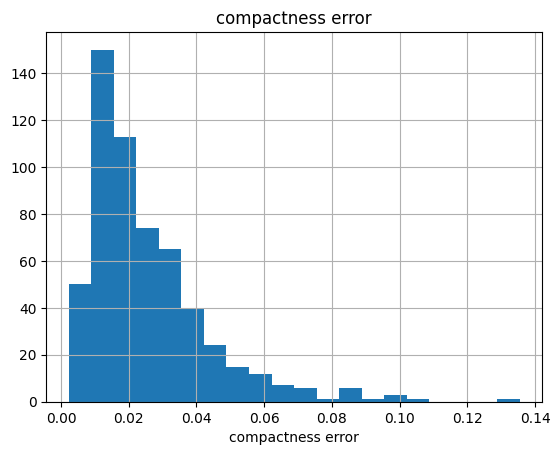

count    569.000000
mean       0.031894
std        0.030186
min        0.000000
5%         0.003253
10%        0.007726
20%        0.013212
30%        0.016980
40%        0.020456
50%        0.025890
60%        0.030544
70%        0.037362
80%        0.046404
90%        0.058520
95%        0.078936
max        0.396000
Name: concavity error, dtype: float64


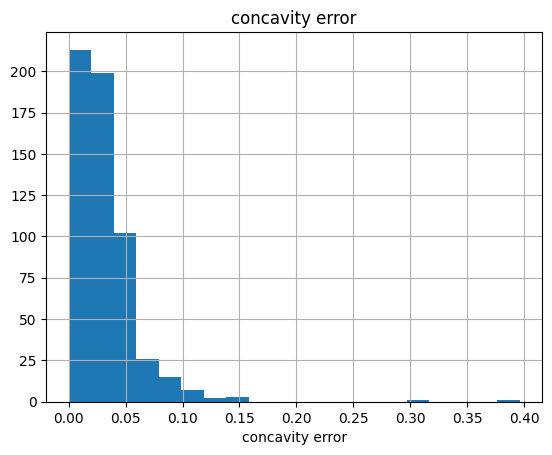

count    569.000000
mean       0.011796
std        0.006170
min        0.000000
5%         0.003831
10%        0.005493
20%        0.006893
30%        0.008465
40%        0.009617
50%        0.010930
60%        0.012410
70%        0.013700
80%        0.015812
90%        0.018688
95%        0.022884
max        0.052790
Name: concave points error, dtype: float64


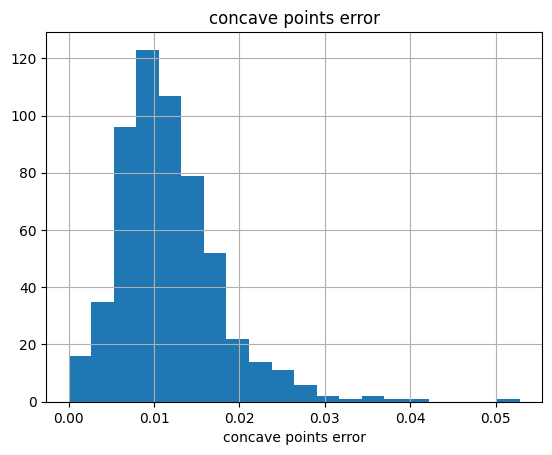

count    569.000000
mean       0.020542
std        0.008266
min        0.007882
5%         0.011758
10%        0.013012
20%        0.014540
30%        0.015704
40%        0.017170
50%        0.018730
60%        0.020066
70%        0.021978
80%        0.025680
90%        0.030120
95%        0.034988
max        0.078950
Name: symmetry error, dtype: float64


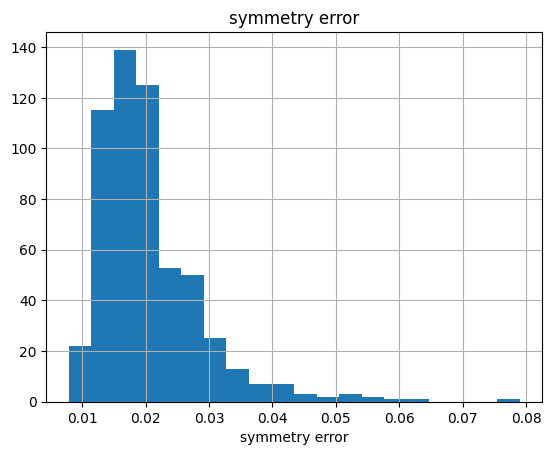

count    569.000000
mean       0.003795
std        0.002646
min        0.000895
5%         0.001522
10%        0.001710
20%        0.002057
30%        0.002382
40%        0.002752
50%        0.003187
60%        0.003611
70%        0.004172
80%        0.004830
90%        0.006185
95%        0.007960
max        0.029840
Name: fractal dimension error, dtype: float64


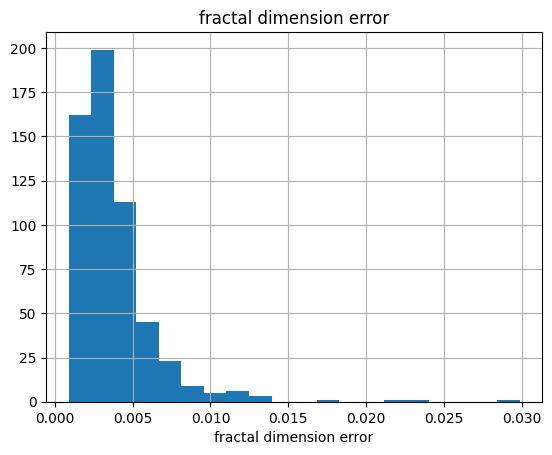

count    569.000000
mean      16.269190
std        4.833242
min        7.930000
5%        10.534000
10%       11.234000
20%       12.498000
30%       13.314000
40%       14.008000
50%       14.970000
60%       16.004000
70%       17.386000
80%       20.294000
90%       23.682000
95%       25.640000
max       36.040000
Name: worst radius, dtype: float64


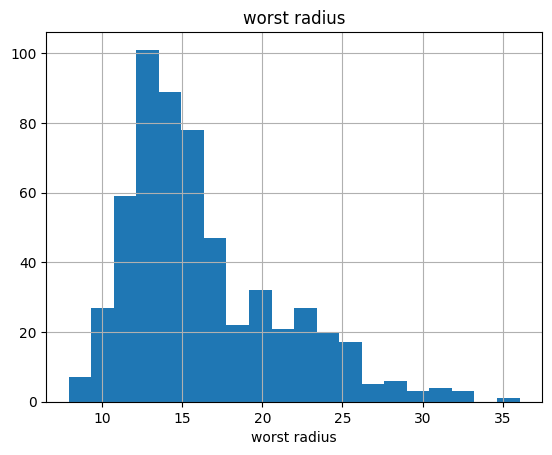

count    569.000000
mean      25.677223
std        6.146258
min       12.020000
5%        16.574000
10%       17.800000
20%       20.176000
30%       21.988000
40%       23.584000
50%       25.410000
60%       26.724000
70%       28.460000
80%       30.908000
90%       33.646000
95%       36.300000
max       49.540000
Name: worst texture, dtype: float64


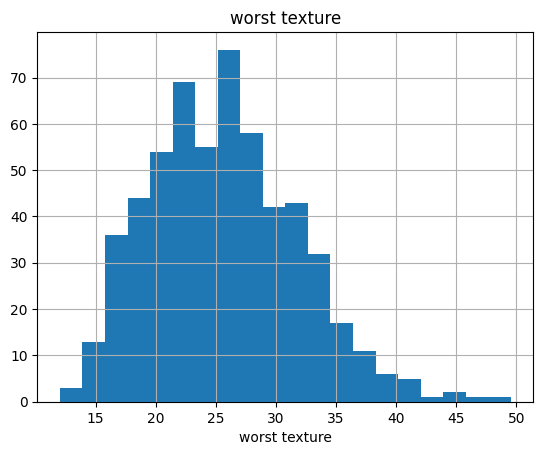

count    569.000000
mean     107.261213
std       33.602542
min       50.410000
5%        67.856000
10%       72.178000
20%       81.402000
30%       86.328000
40%       91.304000
50%       97.660000
60%      105.740000
70%      115.900000
80%      133.500000
90%      157.740000
95%      171.640000
max      251.200000
Name: worst perimeter, dtype: float64


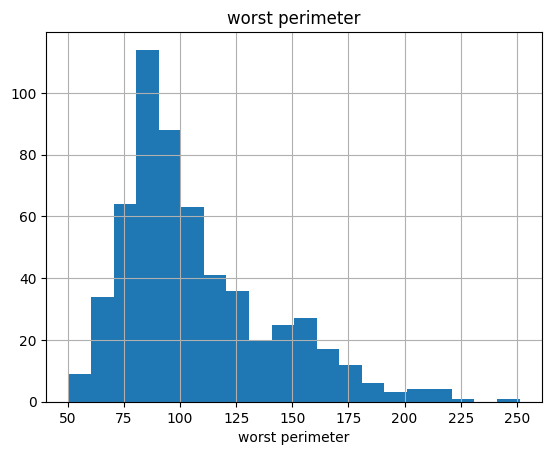

count     569.000000
mean      880.583128
std       569.356993
min       185.200000
5%        331.060000
10%       384.720000
20%       475.980000
30%       544.140000
40%       599.700000
50%       686.500000
60%       781.180000
70%       926.960000
80%      1269.000000
90%      1673.000000
95%      2009.600000
max      4254.000000
Name: worst area, dtype: float64


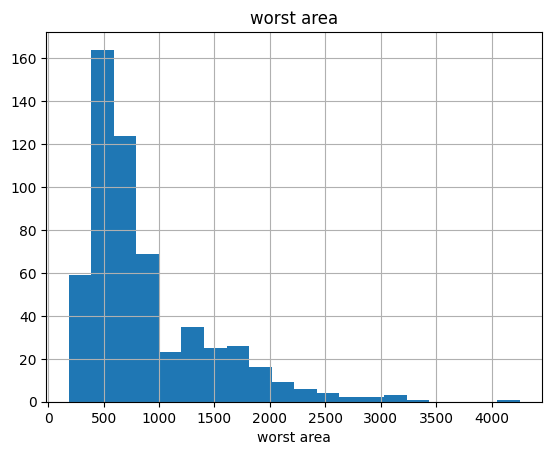

count    569.000000
mean       0.132369
std        0.022832
min        0.071170
5%         0.095734
10%        0.102960
20%        0.112520
30%        0.120740
40%        0.126320
50%        0.131300
60%        0.137680
70%        0.142600
80%        0.150080
90%        0.161480
95%        0.171840
max        0.222600
Name: worst smoothness, dtype: float64


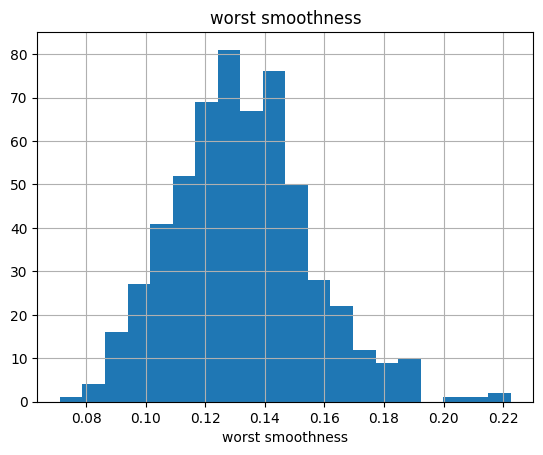

count    569.000000
mean       0.254265
std        0.157336
min        0.027290
5%         0.071196
10%        0.093676
20%        0.125660
30%        0.161400
40%        0.184620
50%        0.211900
60%        0.251400
70%        0.303960
80%        0.367060
90%        0.447840
95%        0.564120
max        1.058000
Name: worst compactness, dtype: float64


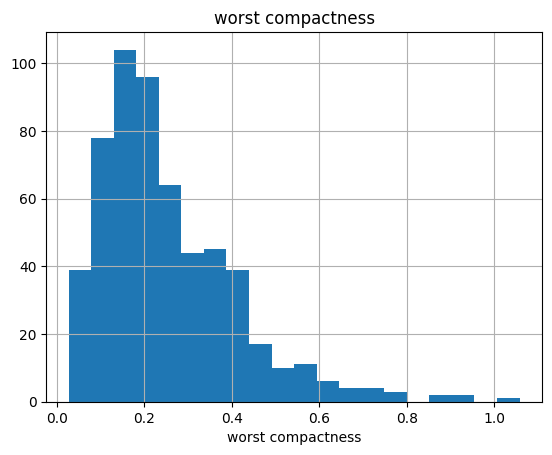

count    569.000000
mean       0.272188
std        0.208624
min        0.000000
5%         0.018360
10%        0.045652
20%        0.091974
30%        0.136880
40%        0.177180
50%        0.226700
60%        0.286600
70%        0.349920
80%        0.419540
90%        0.571320
95%        0.682380
max        1.252000
Name: worst concavity, dtype: float64


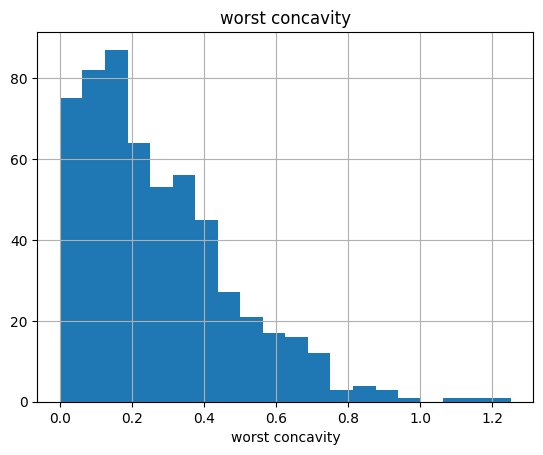

count    569.000000
mean       0.114606
std        0.065732
min        0.000000
5%         0.024286
10%        0.038460
20%        0.058086
30%        0.071656
40%        0.083914
50%        0.099930
60%        0.121800
70%        0.150800
80%        0.177540
90%        0.208940
95%        0.236920
max        0.291000
Name: worst concave points, dtype: float64


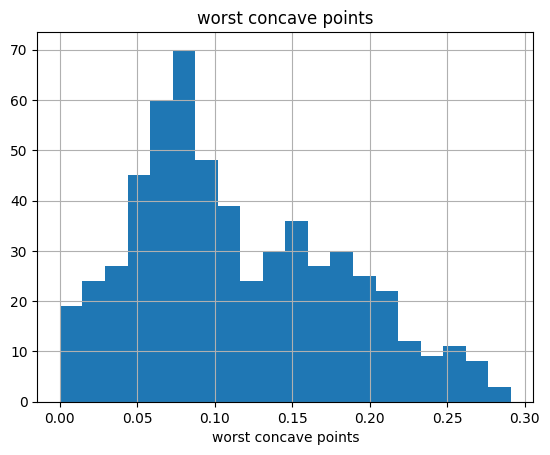

count    569.000000
mean       0.290076
std        0.061867
min        0.156500
5%         0.212700
10%        0.226120
20%        0.243620
30%        0.256520
40%        0.269400
50%        0.282200
60%        0.296480
70%        0.310220
80%        0.325380
90%        0.360080
95%        0.406160
max        0.663800
Name: worst symmetry, dtype: float64


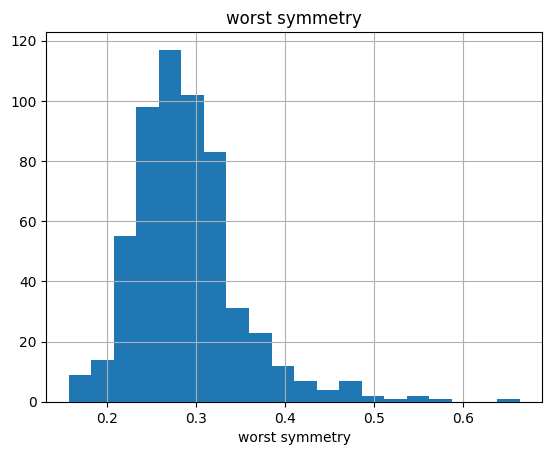

count    569.000000
mean       0.083946
std        0.018061
min        0.055040
5%         0.062558
10%        0.065792
20%        0.069654
30%        0.073462
40%        0.076852
50%        0.080040
60%        0.083202
70%        0.088984
80%        0.095934
90%        0.106320
95%        0.119520
max        0.207500
Name: worst fractal dimension, dtype: float64


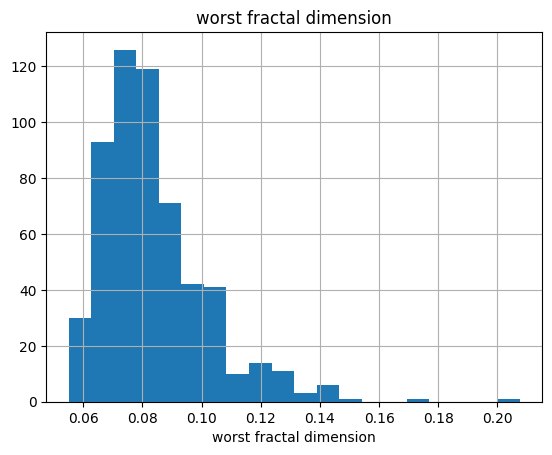

In [30]:
for col in num_cols:
    num_summary(df, col, plot=True)
